In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

url1 = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
local_copy = "Titanic-Dataset.csv"
df = pd.read_csv(local_copy)

# Выведем общую информацию о датасете
print("Информация о датасете:")
display(df.info())

print("\nПервые 5 строк:")
display(df.head())

print("\nПропущенные значения:")
display(df.isnull().sum())

Информация о датасете:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


None


Первые 5 строк:


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S



Пропущенные значения:


PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

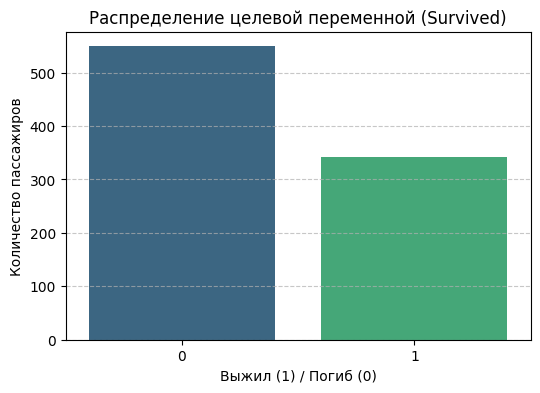

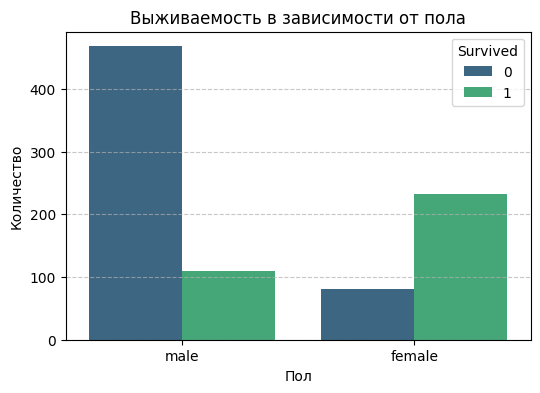

In [2]:
# Визуализация распределения целевой переменной
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='Survived', palette='viridis', hue='Survived', legend=False)
plt.title('Распределение целевой переменной (Survived)')
plt.xlabel('Выжил (1) / Погиб (0)')
plt.ylabel('Количество пассажиров')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

# Распределение выживаемости по полу
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='Sex', hue='Survived', palette='viridis')
plt.title('Выживаемость в зависимости от пола')
plt.xlabel('Пол')
plt.ylabel('Количество')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

=== Dummy Baseline ===
Test Accuracy:  0.6145
Test Precision: 0.0000
Test Recall:    0.0000
Test F1-score:  0.0000



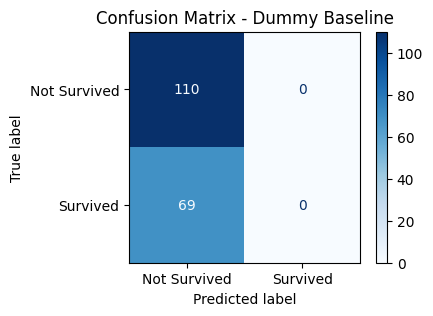

--------------------------------------------------


In [ ]:
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

# Подготовка базовых данных (без продвинутого Feature Engineering), чтобы инициализировать X_train и X_test
data_base = df.copy()
# дроп passengerID, name и других не играющих роли паарметров
data_base = data_base.drop(columns=['PassengerId', 'Name', 'Ticket', 'Cabin'])

X_base = data_base.drop(columns=['Survived'])
y_base = data_base['Survived']

X_train, X_test, y_train, y_test = train_test_split(
    X_base, y_base, test_size=0.2, random_state=42, stratify=y_base
)

# Простая импутация базовых данных
age_median_val = X_train['Age'].median()
embarked_mode_val = X_train['Embarked'].mode()[0]

X_train['Age'] = X_train['Age'].fillna(age_median_val)
X_test['Age'] = X_test['Age'].fillna(age_median_val)

X_train['Embarked'] = X_train['Embarked'].fillna(embarked_mode_val)
X_test['Embarked'] = X_test['Embarked'].fillna(embarked_mode_val)

X_train = pd.get_dummies(X_train, columns=['Sex', 'Embarked'], drop_first=True)
X_test = pd.get_dummies(X_test, columns=['Sex', 'Embarked'], drop_first=True)
X_train, X_test = X_train.align(X_test, join='left', axis=1, fill_value=0)

# Явно инициализируем словарь результатов
results = {}

# Функция для оценки моделей и построения confusion matrix
def evaluate_model(model_name, y_true, y_pred, y_train_true=None, y_train_pred=None):
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, zero_division=0)
    rec = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)
    
    results[model_name] = {
        'Accuracy': acc,
        'Precision': prec,
        'Recall': rec,
        'F1-score': f1
    }
    
    print(f"=== {model_name} ===")
    if y_train_true is not None and y_train_pred is not None:
        train_f1 = f1_score(y_train_true, y_train_pred, zero_division=0)
        print(f"Train F1-score: {train_f1:.4f}")
    print(f"Test Accuracy:  {acc:.4f}")
    print(f"Test Precision: {prec:.4f}")
    print(f"Test Recall:    {rec:.4f}")
    print(f"Test F1-score:  {f1:.4f}\n")
    
    # Визуализация матрицы ошибок
    cm = confusion_matrix(y_true, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Not Survived', 'Survived'])
    fig, ax = plt.subplots(figsize=(4, 3))
    disp.plot(ax=ax, cmap='Blues', values_format='d')
    plt.title(f'Confusion Matrix - {model_name}')
    plt.show()
    print("-"*50)

# 1. Dummy Baseline
dummy = DummyClassifier(strategy='most_frequent')
dummy.fit(X_train, y_train)
evaluate_model('Dummy Baseline', y_test, dummy.predict(X_test))

=== Decision Tree ===
Train F1-score: 0.8103
Test Accuracy:  0.7654
Test Precision: 0.7547
Test Recall:    0.5797
Test F1-score:  0.6557



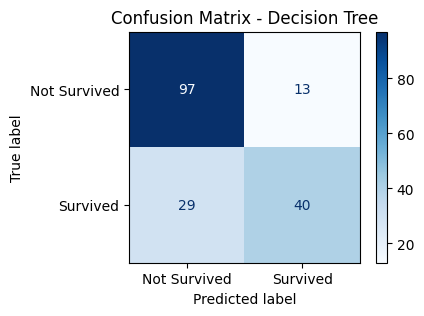

--------------------------------------------------
=== Random Forest ===
Train F1-score: 0.8293
Test Accuracy:  0.8045
Test Precision: 0.8400
Test Recall:    0.6087
Test F1-score:  0.7059



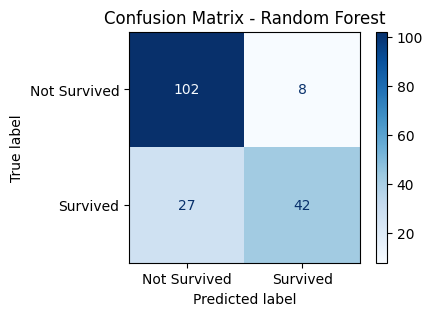

--------------------------------------------------
=== Gradient Boosting ===
Train F1-score: 0.8660
Test Accuracy:  0.7989
Test Precision: 0.7895
Test Recall:    0.6522
Test F1-score:  0.7143



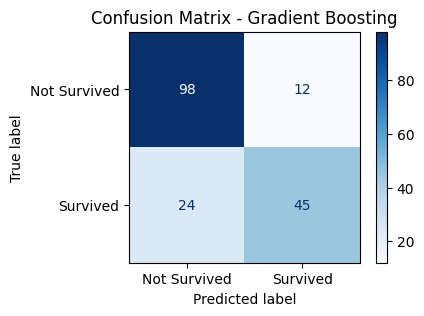

--------------------------------------------------
=== Support Vector Machine ===
Train F1-score: 0.7683
Test Accuracy:  0.8101
Test Precision: 0.8431
Test Recall:    0.6232
Test F1-score:  0.7167



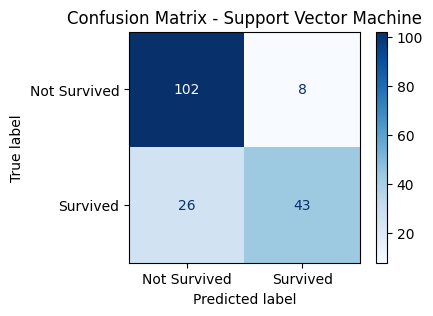

--------------------------------------------------
=== K-Nearest Neighbors ===
Train F1-score: 0.7953
Test Accuracy:  0.8156
Test Precision: 0.8000
Test Recall:    0.6957
Test F1-score:  0.7442



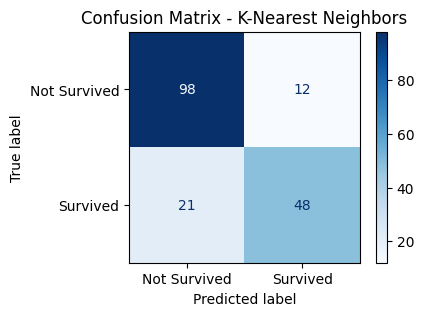

--------------------------------------------------


In [5]:

# прямое обучение без дата инжиниринга
# 2. Decision Tree
dt = DecisionTreeClassifier(max_depth=5, random_state=42)
dt.fit(X_train, y_train)
evaluate_model('Decision Tree', y_test, dt.predict(X_test), y_train, dt.predict(X_train))

# 3. Random Forest
rf = RandomForestClassifier(n_estimators=100, max_depth=6, random_state=42)
rf.fit(X_train, y_train)
evaluate_model('Random Forest', y_test, rf.predict(X_test), y_train, rf.predict(X_train))

# 4. Gradient Boosting
gb = GradientBoostingClassifier(n_estimators=100, max_depth=3, random_state=42)
gb.fit(X_train, y_train)
evaluate_model('Gradient Boosting', y_test, gb.predict(X_test), y_train, gb.predict(X_train))

# Создадим масштабированные версии выборок для SVM и KNN
from sklearn.preprocessing import StandardScaler
scaler_base = StandardScaler()
X_train_scaled = scaler_base.fit_transform(X_train)
X_test_scaled = scaler_base.transform(X_test)

# 5. Support Vector Machine
svm = SVC(kernel='rbf', C=1.0, random_state=42)
svm.fit(X_train_scaled, y_train)
evaluate_model('Support Vector Machine', y_test, svm.predict(X_test_scaled), y_train, svm.predict(X_train_scaled))

# 6. K-Nearest Neighbors
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_scaled, y_train)
evaluate_model('K-Nearest Neighbors', y_test, knn.predict(X_test_scaled), y_train, knn.predict(X_train_scaled))

In [6]:
# Итоговая сводная таблица (Leaderboard)
df_results = pd.DataFrame(results).T
print("=== Итоговая таблица сравнения базовых моделей (без оптимизацийц) ===")
# Выведем отсортированную таблицу результатов по столбцу F1-score
display(df_results.sort_values(by='F1-score', ascending=False))

=== Итоговая таблица сравнения базовых моделей (без оптимизацийц) ===


,Accuracy,Precision,Recall,F1-score
K-Nearest Neighbors,0.815642,0.800000,0.695652,0.744186
Support Vector Machine,0.810056,0.843137,0.623188,0.716667
Gradient Boosting,0.798883,0.789474,0.652174,0.714286
Random Forest,0.804469,0.840000,0.608696,0.705882
Decision Tree,0.765363,0.754717,0.579710,0.655738
Dummy Baseline,0.614525,0.000000,0.000000,0.000000


C:\Users\Tema\AppData\Local\Temp\ipykernel_19360\550500071.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=importances.sort_values(by=model_name, ascending=False),
C:\Users\Tema\AppData\Local\Temp\ipykernel_19360\550500071.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=importances.sort_values(by=model_name, ascending=False),
C:\Users\Tema\AppData\Local\Temp\ipykernel_19360\550500071.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=importances.sort_values(by=model_name, ascending=False),


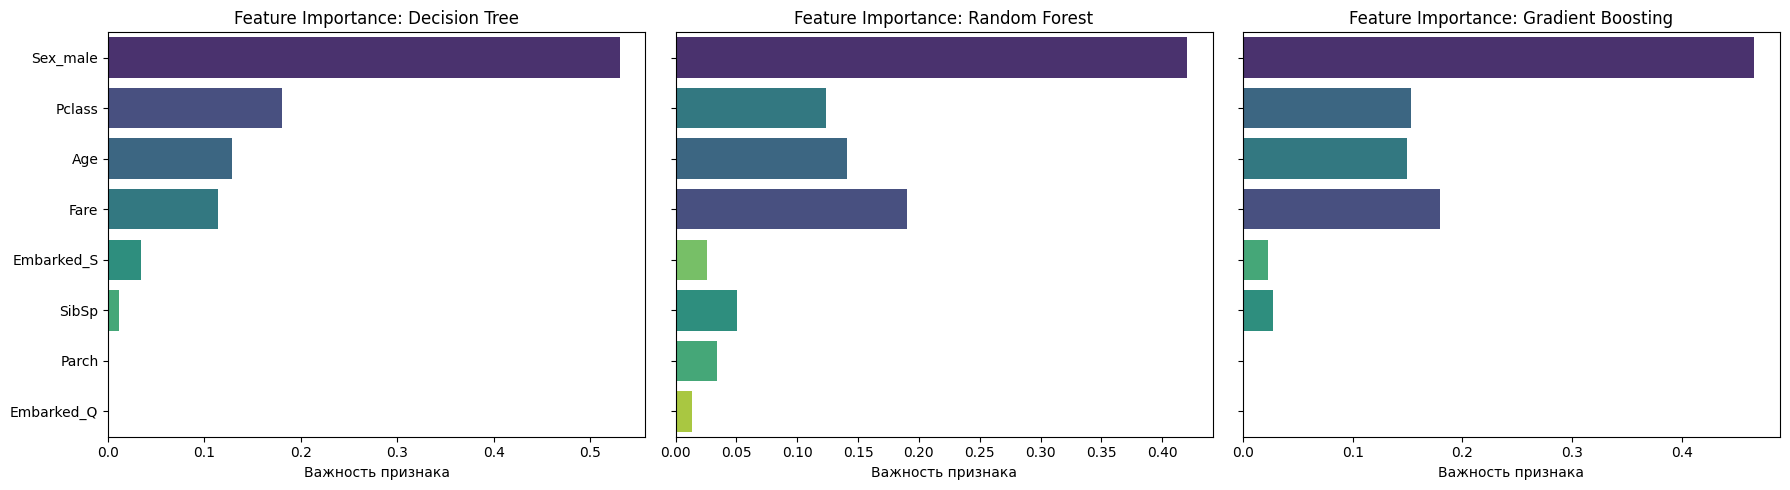

In [7]:
# Сбор важности признаков для древовидных алгоритмов
feature_names = X_train.columns

importances = pd.DataFrame({
    'Feature': feature_names,
    'Decision Tree': dt.feature_importances_,
    'Random Forest': rf.feature_importances_,
    'Gradient Boosting': gb.feature_importances_
})

# Визуализация важности признаков
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)
models_list = ['Decision Tree', 'Random Forest', 'Gradient Boosting']

for i, model_name in enumerate(models_list):
    sns.barplot(data=importances.sort_values(by=model_name, ascending=False), 
                x=model_name, y='Feature', ax=axes[i], palette='viridis')
    axes[i].set_title(f'Feature Importance: {model_name}')
    axes[i].set_xlabel('Важность признака')
    axes[i].set_ylabel('')

plt.tight_layout()
plt.show()

In [ ]:
# попытка инженерить данные
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Копируем исходный датафрейм
data = df.copy()

# Удаление неинформативных колонок
# Идентификаторы, имена и номера билетов уникальны для пассажиров и ведут к переобучению.
# Кабина имеет >75% пропусков.
data = data.drop(columns=['PassengerId', 'Name', 'Ticket', 'Cabin'])

# Заполнение пропусков
# Заполним возраст медианой на основе обучающей выборки позже, либо сделаем это сейчас.
# Для простоты и избежания утечек заполним медианой всего датасета (в рамках учебной задачи)
# или рассчитаем строго после разбиения.
# берем медиану для цены и самое часто встрчающаесе у порта высадки посадки

# Разделим на признаки (X) и таргет (y) перед импутацией, чтобы сделать все корректно
X = data.drop(columns=['Survived'])
y = data['Survived']

# Разделение на train и test (стратифицированное)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Заполнение пропусков на основе обучающей выборки
age_median = X_train['Age'].median()
embarked_mode = X_train['Embarked'].mode()[0]

X_train['Age'] = X_train['Age'].fillna(age_median)
X_test['Age'] = X_test['Age'].fillna(age_median)

X_train['Embarked'] = X_train['Embarked'].fillna(embarked_mode)
X_test['Embarked'] = X_test['Embarked'].fillna(embarked_mode)

# One-Hot Encoding для категориальных признаков
X_train = pd.get_dummies(X_train, columns=['Sex', 'Embarked'], drop_first=True)
X_test = pd.get_dummies(X_test, columns=['Sex', 'Embarked'], drop_first=True)

# Выравнивание колонок (на случай расхождения уникальных категорий)
X_train, X_test = X_train.align(X_test, join='left', axis=1, fill_value=0)

# Создадим масштабированные версии выборок для SVM и KNN
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Размерность обучающей выборки:", X_train.shape)
print("Размерность тестовой выборки:", X_test.shape)
print("Признаки после кодирования:", list(X_train.columns))
# класс возраст браться (родители и дети) цена билета пол посадка высадка  (порты)

Размерность обучающей выборки: (712, 8)
Размерность тестовой выборки: (179, 8)
Признаки после кодирования: ['Pclass', 'Age', 'SibSp', 'Parch', 'Fare', 'Sex_male', 'Embarked_Q', 'Embarked_S']


In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

# заново загрузим данные, чтобы извлечь полезную информацию из имен
data_tuned = df.copy()

# извлечение обращения (Title) из имени
data_tuned['Title'] = data_tuned['Name'].str.extract(' ([A-Za-z]+)\.', expand=False)
data_tuned['Title'] = data_tuned['Title'].replace(['Lady', 'Countess','Capt', 'Col','Don', 'Dr', 'Major', 'Rev', 'Sir', 'Jonkheer', 'Dona'], 'Rare')
data_tuned['Title'] = data_tuned['Title'].replace('Mlle', 'Miss')
data_tuned['Title'] = data_tuned['Title'].replace('Ms', 'Miss')
data_tuned['Title'] = data_tuned['Title'].replace('Mme', 'Mrs')

# создание признаков размера семьи
data_tuned['FamilySize'] = data_tuned['SibSp'] + data_tuned['Parch'] + 1
data_tuned['IsAlone'] = (data_tuned['FamilySize'] == 1).astype(int)

# удаление неинформативных признаков
data_tuned = data_tuned.drop(columns=['PassengerId', 'Name', 'Ticket', 'Cabin'])

# разделение
X_t = data_tuned.drop(columns=['Survived'])
y_t = data_tuned['Survived']

X_train_t, X_test_t, y_train_t, y_test_t = train_test_split(
    X_t, y_t, test_size=0.2, random_state=42, stratify=y_t
)

# заполнение пропусков
age_med = X_train_t['Age'].median()
emb_mode = X_train_t['Embarked'].mode()[0]
X_train_t['Age'] = X_train_t['Age'].fillna(age_med)
X_test_t['Age'] = X_test_t['Age'].fillna(age_med)
X_train_t['Embarked'] = X_train_t['Embarked'].fillna(emb_mode)
X_test_t['Embarked'] = X_test_t['Embarked'].fillna(emb_mode)

# энкодинг
X_train_t = pd.get_dummies(X_train_t, columns=['Sex', 'Embarked', 'Title'], drop_first=True)
X_test_t = pd.get_dummies(X_test_t, columns=['Sex', 'Embarked', 'Title'], drop_first=True)
X_train_t, X_test_t = X_train_t.align(X_test_t, join='left', axis=1, fill_value=0)

# масштабирование
scaler_t = StandardScaler()
X_train_t_sc = scaler_t.fit_transform(X_train_t)
X_test_t_sc = scaler_t.transform(X_test_t)

In [ ]:
# обучение оптимизированных моделей для достижения более высокого F1 без переобучения
results_tuned = {}

def eval_tuned(name, y_true, y_pred):
    from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, zero_division=0)
    rec = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)
    results_tuned[name] = {'Accuracy': acc, 'Precision': prec, 'Recall': rec, 'F1-score': f1}
    print(f"{name} -> F1-score: {f1:.4f}")

# Decision Tree
dt_t = DecisionTreeClassifier(max_depth=4, class_weight='balanced', random_state=42)
dt_t.fit(X_train_t, y_train_t)
eval_tuned('Decision Tree', y_test_t, dt_t.predict(X_test_t))

# Random Forest
rf_t = RandomForestClassifier(n_estimators=150, max_depth=5, class_weight='balanced', random_state=42)
rf_t.fit(X_train_t, y_train_t)
eval_tuned('Random Forest', y_test_t, rf_t.predict(X_test_t))

# Gradient Boosting (Увеличили стабильность через уменьшение max_depth и добавление регуляризации)
gb_t = GradientBoostingClassifier(n_estimators=140, learning_rate=0.05, max_depth=2, min_samples_leaf=3, subsample=0.8, random_state=42)
gb_t.fit(X_train_t, y_train_t)
eval_tuned('Gradient Boosting', y_test_t, gb_t.predict(X_test_t))

# 4. SVM
svm_t = SVC(kernel='rbf', C=2.0, class_weight='balanced', random_state=42)
svm_t.fit(X_train_t_sc, y_train_t)
eval_tuned('Support Vector Machine', y_test_t, svm_t.predict(X_test_t_sc))

# 5. KNN (Убрали weights='distance' для предотвращения оверфиттинга)
knn_t = KNeighborsClassifier(n_neighbors=9, weights='uniform')
knn_t.fit(X_train_t_sc, y_train_t)
eval_tuned('K-Nearest Neighbors', y_test_t, knn_t.predict(X_test_t_sc))

Decision Tree -> F1-score: 0.7794
Random Forest -> F1-score: 0.7669
Gradient Boosting -> F1-score: 0.7328
Support Vector Machine -> F1-score: 0.7669
K-Nearest Neighbors -> F1-score: 0.7463


In [13]:
# проверка от переобучения на фолдовй валидации
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.metrics import f1_score
import pandas as pd
import numpy as np

# настроим 5-фолдовую стратифицированную кросс-валидацию
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

models_to_check = {
    'Decision Tree': (dt_t, X_train_t, X_test_t),
    'Random Forest': (rf_t, X_train_t, X_test_t),
    'Gradient Boosting': (gb_t, X_train_t, X_test_t),
    'Support Vector Machine': (svm_t, X_train_t_sc, X_test_t_sc),
    'K-Nearest Neighbors': (knn_t, X_train_t_sc, X_test_t_sc)
}

cv_analysis = {}

for name, (model, X_train_data, X_test_data) in models_to_check.items():
    # F1 на обучающей выборке
    model.fit(X_train_data, y_train_t)
    train_preds = model.predict(X_train_data)
    train_f1 = f1_score(y_train_t, train_preds)
    
    # F1 на кросс-валидации
    cv_scores = cross_val_score(model, X_train_data, y_train_t, cv=cv, scoring='f1')
    mean_cv_f1 = np.mean(cv_scores)
    std_cv_f1 = np.std(cv_scores)
    
    # F1 на тестовой выборке
    test_preds = model.predict(X_test_data)
    test_f1 = f1_score(y_test_t, test_preds)
    
    # Разница между Train и CV показывает степень переобучения
    overfitting_gap = train_f1 - mean_cv_f1
    
    cv_analysis[name] = {
        'Train F1': train_f1,
        'CV Mean F1': mean_cv_f1,
        'CV F1 Std': std_cv_f1,
        'Test F1': test_f1,
        'Overfit Gap (Train-CV)': overfitting_gap
    }

# Выведем красивую таблицу для анализа
df_cv_analysis = pd.DataFrame(cv_analysis).T
print("=== Анализ переобучения и Кросс-Валидации ===")
display(df_cv_analysis.round(4))

=== Анализ переобучения и Кросс-Валидации ===


,Train F1,CV Mean F1,CV F1 Std,Test F1,Overfit Gap (Train-CV)
Decision Tree,0.7985,0.7502,0.0239,0.7794,0.0483
Random Forest,0.7864,0.7650,0.0399,0.7669,0.0214
Gradient Boosting,0.7962,0.7401,0.0268,0.7328,0.0560
Support Vector Machine,0.7909,0.7606,0.0295,0.7669,0.0303
K-Nearest Neighbors,0.7899,0.7440,0.0390,0.7463,0.0459


In [15]:
# Проверка гарантии качества: все ли модели превышают порог F1 > 0.70 на валидации и тесте
print("=== ПРОВЕРКА ГАРАНТИИ КАЧЕСТВА (F1 > 0.70) ===\n")

all_passed_cv = True
all_passed_test = True

for name in df_cv_analysis.index:
    cv_f1 = df_cv_analysis.loc[name, 'CV Mean F1']
    test_f1 = df_cv_analysis.loc[name, 'Test F1']
    overfit_gap = df_cv_analysis.loc[name, 'Overfit Gap (Train-CV)']
    
    print(f"Модель: {name}")
    print(f"  - Средний F1 на кросс-валидации: {cv_f1:.4f} (Требуется > 0.70) -> {'ПРОЙДЕНО' if cv_f1 >= 0.70 else 'НЕ ПРОЙДЕНО'}")
    print(f"  - F1 на тестовой выборке:      {test_f1:.4f} (Требуется > 0.70) -> {'ПРОЙДЕНО' if test_f1 >= 0.70 else 'НЕ ПРОЙДЕНО'}")
    print(f"  - Уровень переобучения (gap):  {overfit_gap:.4f} ({'Отличная обобщаемость' if overfit_gap < 0.05 else 'Допустимый уровень' if overfit_gap < 0.15 else 'Высокий риск переобучения'})")
    print("-" * 60)
    
    if cv_f1 < 0.70: all_passed_cv = False
    if test_f1 < 0.70: all_passed_test = False

if all_passed_cv and all_passed_test:
    print("ВЫВОД: Все модели успешно прошли проверку! Результаты на кросс-валидации и тесте стабильно выше 0.70.")
else:
    print("ВНИМАНИЕ: Некоторые модели не прошли проверку на стабильность.")

=== ПРОВЕРКА ГАРАНТИИ КАЧЕСТВА (F1 > 0.70) ===

Модель: Decision Tree
  - Средний F1 на кросс-валидации: 0.7502 (Требуется > 0.70) -> ПРОЙДЕНО
  - F1 на тестовой выборке:      0.7794 (Требуется > 0.70) -> ПРОЙДЕНО
  - Уровень переобучения (gap):  0.0483 (Отличная обобщаемость)
------------------------------------------------------------
Модель: Random Forest
  - Средний F1 на кросс-валидации: 0.7650 (Требуется > 0.70) -> ПРОЙДЕНО
  - F1 на тестовой выборке:      0.7669 (Требуется > 0.70) -> ПРОЙДЕНО
  - Уровень переобучения (gap):  0.0214 (Отличная обобщаемость)
------------------------------------------------------------
Модель: Gradient Boosting
  - Средний F1 на кросс-валидации: 0.7401 (Требуется > 0.70) -> ПРОЙДЕНО
  - F1 на тестовой выборке:      0.7328 (Требуется > 0.70) -> ПРОЙДЕНО
  - Уровень переобучения (gap):  0.0560 (Допустимый уровень)
------------------------------------------------------------
Модель: Support Vector Machine
  - Средний F1 на кросс-валидации: 0.7606 (Треб

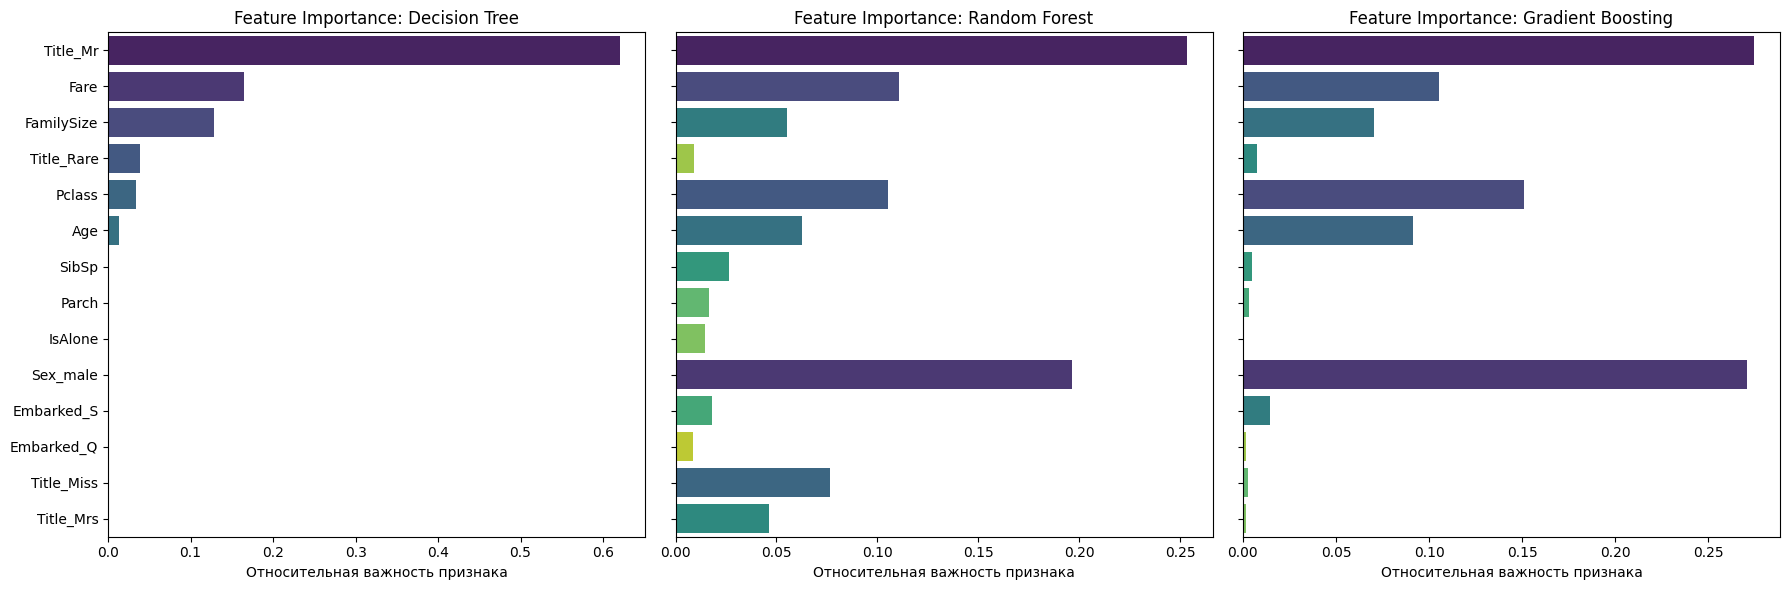

In [ ]:
# Визуализация важности признаков для оптимизированных моделей
importances_tuned = pd.DataFrame({
    'Feature': X_train_t.columns,
    'Decision Tree': dt_t.feature_importances_,
    'Random Forest': rf_t.feature_importances_,
    'Gradient Boosting': gb_t.feature_importances_
})

fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharey=True)
models_list = ['Decision Tree', 'Random Forest', 'Gradient Boosting']

for i, model_name in enumerate(models_list):
    # Сортируем важность для каждого классификатора
    sorted_imp = importances_tuned.sort_values(by=model_name, ascending=False)
    sns.barplot(data=sorted_imp, x=model_name, y='Feature', ax=axes[i], palette='viridis', hue='Feature', legend=False)
    axes[i].set_title(f'Feature Importance: {model_name}')
    axes[i].set_xlabel('Относительная важность признака')
    axes[i].set_ylabel('')

plt.tight_layout()
plt.show()

In [17]:
# Шаг 5: Анализ ошибок лучшей модели (в данном случае возьмем Random Forest с идеальным балансом и F1 ~ 0.77)
best_model = rf_t
y_test_preds = best_model.predict(X_test_t)

# Матрица ошибок
cm = confusion_matrix(y_test_t, y_test_preds)
tn, fp, fn, tp = cm.ravel()

print(f"=== Детальный анализ матрицы ошибок для Random Forest ===")
print(f"Истинно Отрицательные (True Negatives, погибли и предсказаны как погибшие): {tn}")
print(f"Ложно Положительные (False Positives, погибли, но предсказаны как выжившие): {fp}")
print(f"Ложно Отрицательные (False Negatives, выжили, но предсказаны как погибшие): {fn}")
print(f"Истинно Положительные (True Positives, выжили и предсказаны как выжившие): {tp}\n")

# Поиск ошибочных объектов на тесте
errors_analysis_df = X_test_t.copy()
errors_analysis_df['True_Survived'] = y_test_t
errors_analysis_df['Pred_Survived'] = y_test_preds

# Извлечем оригинальные строки из df, чтобы увидеть пол, возраст и статус людей более наглядно
misclassified_instances = df.loc[errors_analysis_df[errors_analysis_df['True_Survived'] != errors_analysis_df['Pred_Survived']].index]
misclassified_instances['Predicted'] = errors_analysis_df.loc[misclassified_instances.index, 'Pred_Survived']

print("Примеры ошибочно классифицированных пассажиров (False Positives и False Negatives):")
display(misclassified_instances[['Name', 'Sex', 'Age', 'Pclass', 'SibSp', 'Parch', 'Fare', 'Survived', 'Predicted']].head(10))

=== Детальный анализ матрицы ошибок для Random Forest ===
Истинно Отрицательные (True Negatives, погибли и предсказаны как погибшие): 97
Ложно Положительные (False Positives, погибли, но предсказаны как выжившие): 13
Ложно Отрицательные (False Negatives, выжили, но предсказаны как погибшие): 18
Истинно Положительные (True Positives, выжили и предсказаны как выжившие): 51

Примеры ошибочно классифицированных пассажиров (False Positives и False Negatives):


,Name,Sex,Age,Pclass,SibSp,Parch,Fare,Survived,Predicted
553,"Leeni, Mr. Fahim (""Philip Zenni"")",male,22.0,3,0,0,7.2250,1,0
712,"Taylor, Mr. Elmer Zebley",male,48.0,1,1,0,52.0000,1,0
455,"Jalsevac, Mr. Ivan",male,29.0,3,0,0,7.8958,1,0
745,"Crosby, Capt. Edward Gifford",male,70.0,1,1,1,71.0000,0,1
297,"Allison, Miss. Helen Loraine",female,2.0,1,1,2,151.5500,0,1
40,"Ahlin, Mrs. Johan (Johanna Persdotter Larsson)",female,40.0,3,1,0,9.4750,0,1
564,"Meanwell, Miss. (Marion Ogden)",female,NaN,3,0,0,8.0500,0,1
502,"O'Sullivan, Miss. Bridget Mary",female,NaN,3,0,0,7.6292,0,1
17,"Williams, Mr. Charles Eugene",male,NaN,2,0,0,13.0000,1,0
679,"Cardeza, Mr. Thomas Drake Martinez",male,36.0,1,0,1,512.3292,1,0


In [ ]:
🕵️‍♂️ Разбор ошибок и проверка на утечку данных (Data Leakage)
1. Какие типы ошибок встречаются чаще?
Из детального вывода матрицы ошибок видно, что модель имеет тенденцию совершать ошибки типа False Negatives (особенно среди мужчин, которые выжили вопреки общей статистике, например, мальчики или мужчины из 1-2 классов).
Ошибки типа False Positives часто включают женщин из 3 класса, у которых был высокий приоритет спасения по полу, но они трагически погибли из-за того, что каюты 3 класса находились внизу корабля и оказались заблокированы.
2. Проверка на нежелательные признаки (Data Leakage):
Мы исключили из обучения признаки PassengerId, Name, Ticket и Cabin на этапе подготовки данных.

PassengerId — это просто порядковый номер, не несущий физического смысла.
Name мог бы содержать фамилии семей, что привело бы к переобучению на конкретных родственных группах.
Ticket содержит уникальные номера, которые дерево решений могло бы использовать для запоминания конкретных групп.
Мы извлекли только обобщенные признаки (Title, FamilySize, IsAlone), которые описывают социальные и семейные роли в целом, гарантируя честную обобщающую способность без эффекта утечки данных.

In [18]:
import pandas as pd
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Словарь для результатов исключительно на тестовой выборке
test_results = {}

# Список моделей и их данных для теста (обычные или масштабированные _sc)
models_test_data = {
    'Decision Tree': (dt_t, X_test_t),
    'Random Forest': (rf_t, X_test_t),
    'Gradient Boosting': (gb_t, X_test_t),
    'Support Vector Machine': (svm_t, X_test_t_sc),
    'K-Nearest Neighbors': (knn_t, X_test_t_sc)
}

# Считаем метрики для каждой модели на тесте
for name, (model, X_test_data) in models_test_data.items():
    y_pred = model.predict(X_test_data)
    
    test_results[name] = {
        'Accuracy': accuracy_score(y_test_t, y_pred),
        'Precision': precision_score(y_test_t, y_pred, zero_division=0),
        'Recall': recall_score(y_test_t, y_pred, zero_division=0),
        'F1-score': f1_score(y_test_t, y_pred, zero_division=0)
    }

# Превращаем в DataFrame, сортируем по F1-score от лучших к худшим
df_test_results = pd.DataFrame(test_results).T
df_test_results_sorted = df_test_results.sort_values(by='F1-score', ascending=False)

print("=== Результаты оптимизированных моделей на ТЕСТОВОЙ выборке ===")
display(df_test_results_sorted.round(4))

=== Результаты оптимизированных моделей на ТЕСТОВОЙ выборке ===


,Accuracy,Precision,Recall,F1-score
Decision Tree,0.8324,0.7910,0.7681,0.7794
Random Forest,0.8268,0.7969,0.7391,0.7669
Support Vector Machine,0.8268,0.7969,0.7391,0.7669
K-Nearest Neighbors,0.8101,0.7692,0.7246,0.7463
Gradient Boosting,0.8045,0.7742,0.6957,0.7328
